In [ ]:
import os, sys
REPO = "https://github.com/salsyaniditiani-commits/simuteh--2330511061-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

if not os.path.exists("data/sintetis/citra"):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Isi src:", os.listdir("../src"))

Cloning into '/content/simuteh'...
remote: Enumerating objects: 162, done.
remote: Counting objects: 100% (162/162), done.
remote: Compressing objects: 100% (140/140), done.
remote: Total 162 (delta 19), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (162/162), 19.29 MiB | 15.25 MiB/s, done.
Resolving deltas: 100% (19/19), done.
Selesai: 60 citra tersimpan di data/sintetis
Folder kerja: /content/simuteh/notebook
Jumlah citra: 60
Isi src: ['utils_cv.py', 'buat_dataset_sintetis.py', 'praproses.py']


KB kanal B   : 2.09
KB kanal G   : 0.80
KB kanal R   : 8.20
KB kanal Gray: 4.20
KB kanal H   : 5.95
KB kanal S   : 1.48
KB kanal V   : 2.09


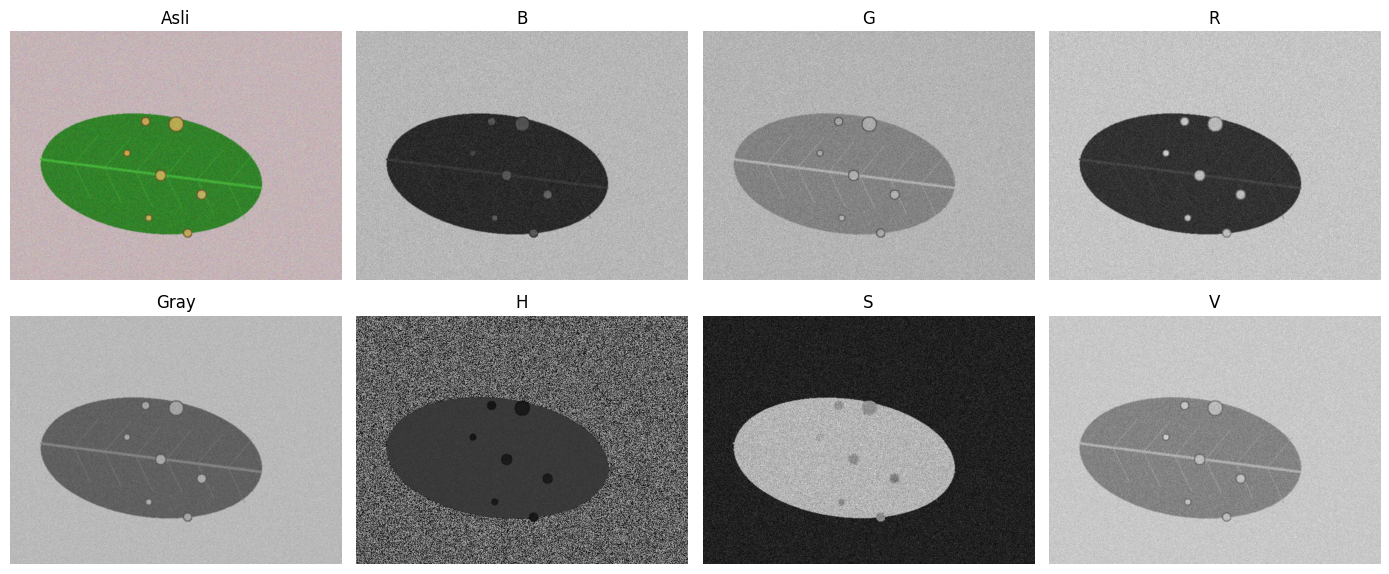

In [ ]:
import cv2
from utils_cv import baca, tampil, kontras_bercak

nama = "teh_041.png"                 # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [ ]:
# Sampling: perkecil lalu perbesar kembali ke ukuran semula
import numpy as np
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(
        gray,
        None,
        fx=fx,
        fy=fx,
        interpolation=cv2.INTER_AREA
    )

    besar = cv2.resize(
        kecil,
        (gray.shape[1], gray.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    kb = kontras_bercak(besar, md, mb)

    print(f"fx={fx}: ukuran {kecil.shape}, KB={kb:.2f}")


# Kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)

    kuant = (gray // langkah) * langkah

    jumlah_level = len(np.unique(kuant))
    kb = kontras_bercak(kuant, md, mb)

    print(f"k={k}: {jumlah_level} level, KB={kb:.2f}")

fx=0.5: ukuran (240, 320), KB=5.54
fx=0.2: ukuran (96, 128), KB=4.98
fx=0.1: ukuran (48, 64), KB=3.57
fx=0.05: ukuran (24, 32), KB=1.54
k=1: 2 level, KB=5.19
k=2: 3 level, KB=5.22
k=3: 6 level, KB=2.56
k=4: 11 level, KB=3.82
k=8: 159 level, KB=4.20


Perbandingan citra

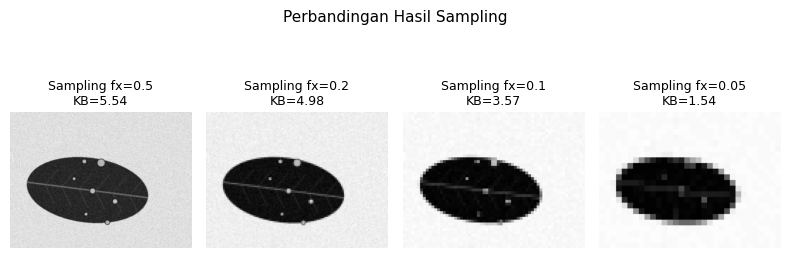

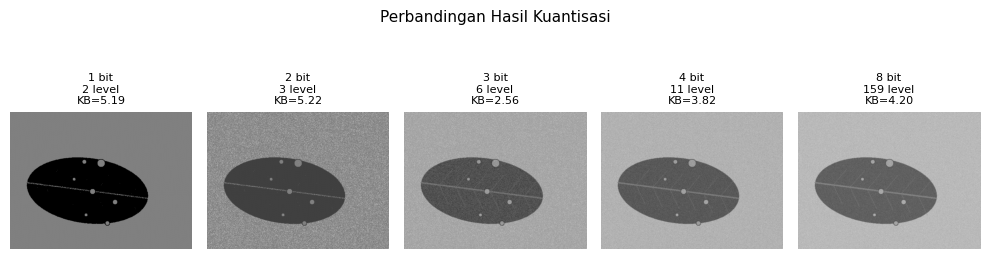

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Perbandingan hasil sampling
faktor_sampling = [0.5, 0.2, 0.1, 0.05]

fig, axes = plt.subplots(1, 4, figsize=(8, 3))

for ax, fx in zip(axes, faktor_sampling):
    kecil = cv2.resize(
        gray, None,
        fx=fx, fy=fx,
        interpolation=cv2.INTER_AREA
    )

    besar = cv2.resize(
        kecil,
        gray.shape[::-1],
        interpolation=cv2.INTER_NEAREST
    )

    kb = kontras_bercak(besar, md, mb)

    ax.imshow(besar, cmap="gray")
    ax.set_title(
        f"Sampling fx={fx}\nKB={kb:.2f}",
        fontsize=9
    )
    ax.axis("off")

plt.suptitle(
    "Perbandingan Hasil Sampling",
    fontsize=11,
    y=0.98
)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(
    "../hasil/b2_perbandingan_sampling.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# Perbandingan hasil kuantisasi
bit_kuantisasi = [1, 2, 3, 4, 8]

fig, axes = plt.subplots(1, 5, figsize=(10, 3))

for ax, k in zip(axes, bit_kuantisasi):
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah

    kb = kontras_bercak(kuant, md, mb)
    jumlah_level = len(np.unique(kuant))

    ax.imshow(
        kuant,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    ax.set_title(
        f"{k} bit\n{jumlah_level} level\nKB={kb:.2f}",
        fontsize=8
    )
    ax.axis("off")

plt.suptitle(
    "Perbandingan Hasil Kuantisasi",
    fontsize=11,
    y=0.98
)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(
    "../hasil/b2_perbandingan_kuantisasi.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [ ]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)

    return {
        "B": b,
        "G": g,
        "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h,
        "S": s,
        "V": v
    }

label = pd.read_csv("../data/sintetis/label.csv")

baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(
        f"../data/sintetis/mask_daun/{d.nama_file}", 0)

    m_b = cv2.imread(
        f"../data/sintetis/mask_bercak/{d.nama_file}", 0)

    kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()}

    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

# Membuat tabel berdasarkan kondisi pencahayaan
tabel_kb = (
    pd.DataFrame(baris)
    .groupby("kondisi")[["B", "G", "R", "Gray", "H", "S", "V"]]
    .mean()
    .reindex(["normal", "gelap", "terang", "kontras_rendah", "bayangan"])
    .round(2)
)

print(tabel_kb)

# Menyimpan hasil
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
normal          2.14  1.67  10.95  5.40  8.23  0.98  3.41
gelap           1.11  1.57   9.47  4.65  5.08  0.68  3.36
terang          1.43  0.67   6.14  3.28  4.44  0.55  1.88
kontras_rendah  1.20  0.38   4.25  2.32  2.39  0.24  1.47
bayangan        1.07  0.22   5.39  1.59  4.95  0.74  0.97


2.6

Tabel KB Kelas Ringan


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
normal,1.43,0.34,7.14,2.83,6.11,1.13,1.27
gelap,0.82,0.29,7.52,2.45,5.23,1.02,1.40
terang,1.71,0.60,6.40,2.42,6.16,1.56,0.62
kontras_rendah,0.76,0.34,2.83,1.14,1.34,0.35,0.73
bayangan,1.53,0.38,4.26,0.98,5.30,1.41,0.50



Kanal terbaik berdasarkan rata-rata kelas berat: R
teh_021.png | Kelas Ringan - Normal | Kanal R | KB = 6.01
teh_045.png | Kelas Berat - Bayangan | Kanal R | KB = 4.82


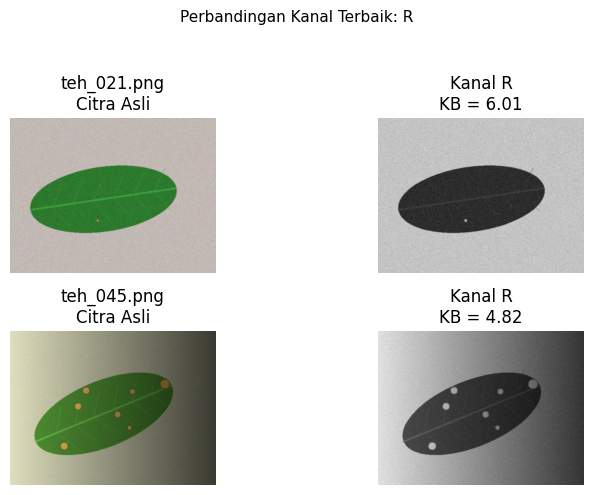

In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

# Fungsi pemisahan kanal warna
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)

    return {
        "B": b,
        "G": g,
        "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h,
        "S": s,
        "V": v
    }


# Membaca label dataset
label = pd.read_csv("../data/sintetis/label.csv")

# Memilih 20 citra kelas ringan
ringan = label[
    (label["kelas"] == "ringan") &
    (label["nama_file"].isin([
        f"teh_{i:03d}.png" for i in range(21, 41)
    ]))
]

baris = []

# Menghitung KB setiap kanal
for _, d in ringan.iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(
        f"../data/sintetis/mask_daun/{d.nama_file}", 0
    )

    m_b = cv2.imread(
        f"../data/sintetis/mask_bercak/{d.nama_file}", 0
    )

    if m_d is None or m_b is None:
        print(f"Mask tidak ditemukan: {d.nama_file}")
        continue

    kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()
    }

    kb["kondisi"] = d.kondisi_cahaya
    kb["nama_file"] = d.nama_file
    baris.append(kb)


# Membuat tabel hasil kelas ringan
hasil_ringan = pd.DataFrame(baris)

tabel_ringan = (
    hasil_ringan
    .groupby("kondisi")[["B", "G", "R", "Gray", "H", "S", "V"]]
    .mean()
    .reindex(["normal", "gelap", "terang", "kontras_rendah", "bayangan"])
    .round(2)
)

print("Tabel KB Kelas Ringan")
display(tabel_ringan)

# Menyimpan hasil
tabel_ringan.to_csv("../hasil/b26_kb_kanal_ringan.csv")

# Menentukan kanal terbaik berdasarkan hasil kelas berat
kanal_terbaik = tabel_kb.mean().idxmax()

print("\nKanal terbaik berdasarkan rata-rata kelas berat:", kanal_terbaik)


# Menampilkan kanal terbaik untuk teh_021 dan teh_045
daftar_tampil = [
    ("teh_021.png", "Kelas Ringan - Normal"),
    ("teh_045.png", "Kelas Berat - Bayangan")
]

fig, axes = plt.subplots(2, 2, figsize=(8, 5))

for i, (nama, keterangan) in enumerate(daftar_tampil):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

    kanal = semua_kanal(img)
    citra_terbaik = kanal[kanal_terbaik]

    kb = kontras_bercak(citra_terbaik, md, mb)

    axes[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{nama}\nCitra Asli")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(citra_terbaik, cmap="gray")
    axes[i, 1].set_title(
        f"Kanal {kanal_terbaik}\nKB = {kb:.2f}"
    )
    axes[i, 1].axis("off")

    print(f"{nama} | {keterangan} | Kanal {kanal_terbaik} | KB = {kb:.2f}")

plt.suptitle(
    f"Perbandingan Kanal Terbaik: {kanal_terbaik}",
    fontsize=11,
    y=0.98
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("../hasil/b26_kanal_terbaik.png", dpi=150)
plt.show()